In [ ]:
import requests
import pandas as pd
from getpass import getpass

API_KEY = getpass("Enter your API key: ")

url = "https://api.quickcommerceapi.com/v1/search"

params = {
    "q": "mobiles",
    "lat": 11.1085,
    "lon": 77.3411,
    "platform": "Flipkart"
}

headers = {
    "X-API-Key": API_KEY
}

response = requests.get(
    url,
    params=params,
    headers=headers,
    timeout=30
)

print("Status code:", response.status_code)

if response.ok:
    result = response.json()
    print("API connection successful!")
    print("Credits remaining:", result.get("credits_remaining"))
else:
    print("Error:", response.text)

Enter your API key: ··········
Status code: 200
API connection successful!
Credits remaining: 79


In [ ]:
print(result.keys())
print(result["data"].keys())
print("Total results:", result["data"]["total_results"])

# Display one product to understand its structure
print(result["data"]["products"][0])

dict_keys(['status', 'request_id', 'credits_remaining', 'data'])
dict_keys(['query', 'platform', 'lat', 'lon', 'total_results', 'products'])
Total results: 37
{'id': 'MOBHPP59ARTH58SM', 'name': 'BOLTT ACE 5G (Sky Blue, 64 GB)', 'brand': 'BOLTT', 'available': True, 'images': ['https://rukminim1.flixcart.com/image/500/500/xif0q/mobile/w/h/m/-original-imahs3pjmz8wssup.jpeg?q=100', 'https://rukminim1.flixcart.com/image/500/500/xif0q/mobile/4/t/1/-original-imahqegrcwsvggjy.jpeg?q=100', 'https://rukminim1.flixcart.com/image/500/500/xif0q/mobile/h/s/5/-original-imahqegrxmh7euqg.jpeg?q=100', 'https://rukminim1.flixcart.com/image/500/500/xif0q/mobile/9/5/3/-original-imahqegr6fnsbhuy.jpeg?q=100', 'https://rukminim1.flixcart.com/image/500/500/xif0q/mobile/i/h/b/-original-imahqegrfsvzrcdp.jpeg?q=100', 'https://rukminim1.flixcart.com/image/500/500/xif0q/mobile/6/j/o/-original-imahqegrvattupzj.jpeg?q=100', 'https://rukminim1.flixcart.com/image/500/500/xif0q/mobile/1/z/o/-original-imahqegrnamrggnb.jp

In [ ]:
products = result["data"]["products"]

df = pd.json_normalize(products)

print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head(10))

Rows and columns: (37, 19)

Column names:
['id', 'name', 'brand', 'available', 'images', 'mrp', 'offer_price', 'quantity', 'deeplink', 'rating', 'rating_count', 'inventory', 'is_ad', 'rank', 'store_id', 'platform.name', 'platform.sla', 'platform.open', 'platform.icon']


,id,name,brand,available,images,mrp,offer_price,quantity,deeplink,rating,rating_count,inventory,is_ad,rank,store_id,platform.name,platform.sla,platform.open,platform.icon
0,MOBHPP59ARTH58SM,"BOLTT ACE 5G (Sky Blue, 64 GB)",BOLTT,True,[https://rukminim1.flixcart.com/image/500/500/...,24999,11999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHPP59ART...,4.1,484,1,False,1,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
1,MOBHPP59BYSJ98M8,"BOLTT EVO (Arctic White, 64 GB)",BOLTT,True,[https://rukminim1.flixcart.com/image/500/500/...,17999,9999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHPP59BYS...,4.1,1434,1,False,2,641601,Flipkart,Delivery by 27th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
2,MOBHMGHHXHYZEAVB,"Samsung Galaxy F07 (Green, 64 GB)",Samsung,True,[https://rukminim1.flixcart.com/image/500/500/...,11999,11999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHMGHHXHY...,4.2,826,1,False,3,641601,Flipkart,Delivery by 27th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
3,MOBHQSFF6MZK4YNP,"vivo T5 Lite 44W 5G (Twilight Shadow, 64 GB)",vivo,True,[https://rukminim1.flixcart.com/image/500/500/...,30999,17999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHQSFF6MZ...,4.3,337,1,False,4,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
4,MOBHN7A8SZ7F9C7T,"realme P4 Lite 5G (Mosaic Green, 64 GB)",realme,True,[https://rukminim1.flixcart.com/image/500/500/...,28999,16249,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHN7A8SZ7...,4.2,1105,1,False,5,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
5,MOBHR3ZYWM7R57PW,"OPPO K14 Plus 5G (Star White, 128 GB)",OPPO,True,[https://rukminim1.flixcart.com/image/500/500/...,61999,32999,6 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHR3ZYWM7...,4.4,602,1,False,6,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
6,MOBHN974GHFYSJNH,MOTOROLA g57 power 5G Snapdragon (Pantone Cors...,MOTOROLA,True,[https://rukminim1.flixcart.com/image/500/500/...,21999,21999,8 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHN974GHF...,4.4,4349,1,False,7,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
7,MOBHQZVX9JGVG3XF,"Ai+ Pulse 2 FE (Blue, 64 GB)",Ai+,True,[https://rukminim1.flixcart.com/image/500/500/...,16999,9999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHQZVX9JG...,4.3,54,1,False,8,641601,Flipkart,Delivery by Tomorrow,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
8,MOBHMGG5SMZEFPTQ,"POCO C85x 5G (Elite Black, 64 GB)",POCO,True,[https://rukminim1.flixcart.com/image/500/500/...,20999,13999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHMGG5SMZ...,4.0,986,1,False,9,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
9,MOBHMJR8NHWYYJJD,"REDMI A7 Pro 5G (Mist Blue, 64 GB)",REDMI,True,[https://rukminim1.flixcart.com/image/500/500/...,15999,14490,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHMJR8NHW...,3.9,549,1,False,10,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...


In [ ]:
df['brand'].value_counts()

,count
brand,
Samsung,13
vivo,5
realme,4
MOTOROLA,3
BOLTT,2
REDMI,2
OPPO,1
Ai+,1
POCO,1


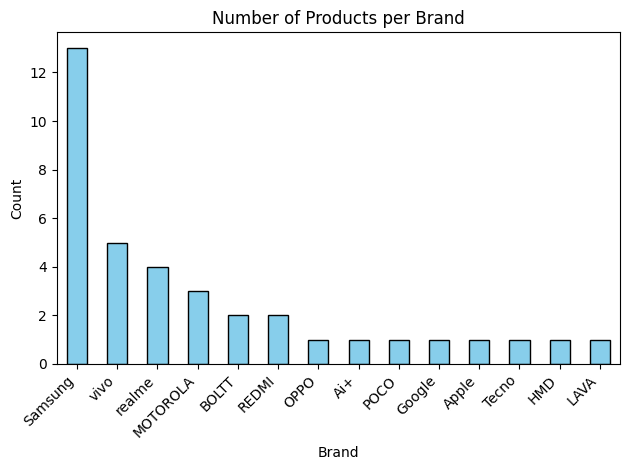

In [ ]:
import matplotlib.pyplot as plt

# Get value counts and plot as a bar chart
df['brand'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')

plt.xlabel('Brand')
plt.ylabel('Count')
plt.title('Number of Products per Brand')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
df.tail()

,id,name,brand,available,images,mrp,offer_price,quantity,deeplink,rating,rating_count,inventory,is_ad,rank,store_id,platform.name,platform.sla,platform.open,platform.icon
32,MOBHQCH6HZZH3BTH,"Samsung Galaxy S25 FE 5G (Navy, 128 GB)",Samsung,True,[https://rukminim1.flixcart.com/image/500/500/...,89999,45999,8 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHQCH6HZZ...,4.5,1290,1,False,40,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
33,MOBHP3W8ESQHPZNP,"realme Narzo 80 Lite (See Blue, 64 GB)",realme,True,[https://rukminim1.flixcart.com/image/500/500/...,16999,13440,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHP3W8ESQ...,4.2,215,1,False,43,641601,Flipkart,Delivery by 27th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
34,MOBHZGPPZAGBEKG3,"LAVA Virat V1 5G (Sonar Gold, 64 GB)",LAVA,True,[https://rukminim1.flixcart.com/image/500/500/...,15999,13499,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHZGPPZAG...,4.1,371,1,False,44,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
35,MOBHPBM6FNMA7ZC7,"vivo T5e (Shadow Grey, 64 GB)",vivo,True,[https://rukminim1.flixcart.com/image/500/500/...,26999,13999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHPBM6FNM...,3.9,12,1,False,45,641601,Flipkart,Delivery by Tomorrow,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...
36,MOBHQC8ZYMX7HHC8,"vivo T5x 5G (Cosmic Green, 256 GB)",vivo,True,[https://rukminim1.flixcart.com/image/500/500/...,56999,34999,8 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHQC8ZYMX...,4.4,2254,1,False,46,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37 entries, 0 to 36
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             37 non-null     object 
 1   name           37 non-null     object 
 2   brand          37 non-null     object 
 3   available      37 non-null     bool   
 4   images         37 non-null     object 
 5   mrp            37 non-null     int64  
 6   offer_price    37 non-null     int64  
 7   quantity       37 non-null     object 
 8   deeplink       37 non-null     object 
 9   rating         37 non-null     float64
 10  rating_count   37 non-null     int64  
 11  inventory      37 non-null     int64  
 12  is_ad          37 non-null     bool   
 13  rank           37 non-null     int64  
 14  store_id       37 non-null     object 
 15  platform.name  37 non-null     object 
 16  platform.sla   37 non-null     object 
 17  platform.open  37 non-null     bool   
 18  platform.ico

In [ ]:
df['discount']=((df['mrp'] - df['offer_price'])/df['mrp'])*100

In [ ]:
df.head()

,id,name,brand,available,images,mrp,offer_price,quantity,deeplink,rating,rating_count,inventory,is_ad,rank,store_id,platform.name,platform.sla,platform.open,platform.icon,discount
0,MOBHPP59ARTH58SM,"BOLTT ACE 5G (Sky Blue, 64 GB)",BOLTT,True,[https://rukminim1.flixcart.com/image/500/500/...,24999,11999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHPP59ART...,4.1,484,1,False,1,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,52.002080
1,MOBHPP59BYSJ98M8,"BOLTT EVO (Arctic White, 64 GB)",BOLTT,True,[https://rukminim1.flixcart.com/image/500/500/...,17999,9999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHPP59BYS...,4.1,1434,1,False,2,641601,Flipkart,Delivery by 27th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,44.446914
2,MOBHMGHHXHYZEAVB,"Samsung Galaxy F07 (Green, 64 GB)",Samsung,True,[https://rukminim1.flixcart.com/image/500/500/...,11999,11999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHMGHHXHY...,4.2,826,1,False,3,641601,Flipkart,Delivery by 27th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,0.000000
3,MOBHQSFF6MZK4YNP,"vivo T5 Lite 44W 5G (Twilight Shadow, 64 GB)",vivo,True,[https://rukminim1.flixcart.com/image/500/500/...,30999,17999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHQSFF6MZ...,4.3,337,1,False,4,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,41.936837
4,MOBHN7A8SZ7F9C7T,"realme P4 Lite 5G (Mosaic Green, 64 GB)",realme,True,[https://rukminim1.flixcart.com/image/500/500/...,28999,16249,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHN7A8SZ7...,4.2,1105,1,False,5,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,43.967033


In [ ]:
df[['brand','discount']].head().sort_values(by='discount',ascending=False)

,brand,discount
0,BOLTT,52.002080
1,BOLTT,44.446914
4,realme,43.967033
3,vivo,41.936837
2,Samsung,0.000000


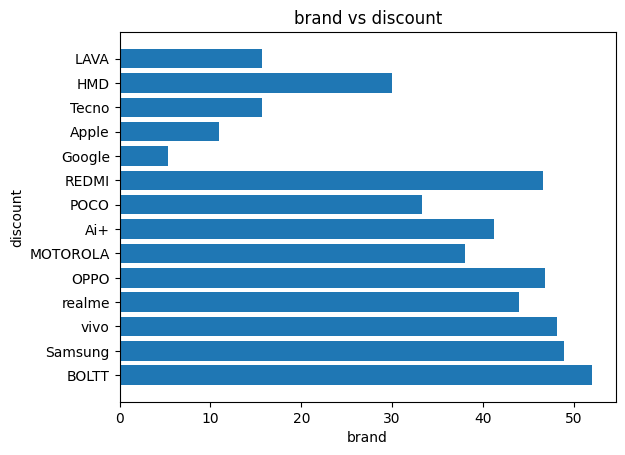

In [ ]:
plt.barh(df['brand'],df['discount'])
plt.xlabel('brand')
plt.ylabel('discount')
plt.title('brand vs discount')
plt.show()

In [ ]:
df[df['offer_price']<20000].head()

,id,name,brand,available,images,mrp,offer_price,quantity,deeplink,rating,rating_count,inventory,is_ad,rank,store_id,platform.name,platform.sla,platform.open,platform.icon,discount
0,MOBHPP59ARTH58SM,"BOLTT ACE 5G (Sky Blue, 64 GB)",BOLTT,True,[https://rukminim1.flixcart.com/image/500/500/...,24999,11999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHPP59ART...,4.1,484,1,False,1,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,52.002080
1,MOBHPP59BYSJ98M8,"BOLTT EVO (Arctic White, 64 GB)",BOLTT,True,[https://rukminim1.flixcart.com/image/500/500/...,17999,9999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHPP59BYS...,4.1,1434,1,False,2,641601,Flipkart,Delivery by 27th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,44.446914
2,MOBHMGHHXHYZEAVB,"Samsung Galaxy F07 (Green, 64 GB)",Samsung,True,[https://rukminim1.flixcart.com/image/500/500/...,11999,11999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHMGHHXHY...,4.2,826,1,False,3,641601,Flipkart,Delivery by 27th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,0.000000
3,MOBHQSFF6MZK4YNP,"vivo T5 Lite 44W 5G (Twilight Shadow, 64 GB)",vivo,True,[https://rukminim1.flixcart.com/image/500/500/...,30999,17999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHQSFF6MZ...,4.3,337,1,False,4,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,41.936837
4,MOBHN7A8SZ7F9C7T,"realme P4 Lite 5G (Mosaic Green, 64 GB)",realme,True,[https://rukminim1.flixcart.com/image/500/500/...,28999,16249,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHN7A8SZ7...,4.2,1105,1,False,5,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,43.967033


In [ ]:
print(df.describe())

                 mrp   offer_price     rating  rating_count  inventory  \
count      37.000000     37.000000  37.000000     37.000000       37.0   
mean    44077.405405  27883.594595   4.294595   1059.648649        1.0   
std     30320.599134  18559.204753   0.201310    918.311833        0.0   
min     11999.000000   9999.000000   3.900000     12.000000        1.0   
25%     20999.000000  13999.000000   4.100000    371.000000        1.0   
50%     30999.000000  20499.000000   4.300000    877.000000        1.0   
75%     55999.000000  34999.000000   4.400000   1434.000000        1.0   
max    104999.000000  88999.000000   4.600000   4349.000000        1.0   

            rank   discount  
count  37.000000  37.000000  
mean   21.351351  33.305778  
std    13.603954  14.571718  
min     1.000000   0.000000  
25%    10.000000  26.088091  
50%    20.000000  38.001520  
75%    33.000000  43.809941  
max    46.000000  52.002080  


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37 entries, 0 to 36
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             37 non-null     object 
 1   name           37 non-null     object 
 2   brand          37 non-null     object 
 3   available      37 non-null     bool   
 4   images         37 non-null     object 
 5   mrp            37 non-null     int64  
 6   offer_price    37 non-null     int64  
 7   quantity       37 non-null     object 
 8   deeplink       37 non-null     object 
 9   rating         37 non-null     float64
 10  rating_count   37 non-null     int64  
 11  inventory      37 non-null     int64  
 12  is_ad          37 non-null     bool   
 13  rank           37 non-null     int64  
 14  store_id       37 non-null     object 
 15  platform.name  37 non-null     object 
 16  platform.sla   37 non-null     object 
 17  platform.open  37 non-null     bool   
 18  platform.ico

In [ ]:
print(df.dtypes)

id                object
name              object
brand             object
available           bool
images            object
mrp                int64
offer_price        int64
quantity          object
deeplink          object
rating           float64
rating_count       int64
inventory          int64
is_ad               bool
rank               int64
store_id          object
platform.name     object
platform.sla      object
platform.open       bool
platform.icon     object
discount         float64
dtype: object


In [ ]:
h=df['offer_price'].to_numpy()

In [ ]:
f=h[h<15000]
print(f)

[11999  9999 11999  9999 13999 14490 13499 11802 13999 14427 13440 13499
 13999]


In [ ]:
df=df.rename(columns={'mrp':'price','platform.sla':'delivery_time'})

In [ ]:
df[df['rating_count']>4].head(50)

,id,name,brand,available,images,price,offer_price,quantity,deeplink,rating,rating_count,inventory,is_ad,rank,store_id,platform.name,delivery_time,platform.open,platform.icon,discount
0,MOBHPP59ARTH58SM,"BOLTT ACE 5G (Sky Blue, 64 GB)",BOLTT,True,[https://rukminim1.flixcart.com/image/500/500/...,24999,11999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHPP59ART...,4.1,484,1,False,1,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,52.002080
1,MOBHPP59BYSJ98M8,"BOLTT EVO (Arctic White, 64 GB)",BOLTT,True,[https://rukminim1.flixcart.com/image/500/500/...,17999,9999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHPP59BYS...,4.1,1434,1,False,2,641601,Flipkart,Delivery by 27th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,44.446914
2,MOBHMGHHXHYZEAVB,"Samsung Galaxy F07 (Green, 64 GB)",Samsung,True,[https://rukminim1.flixcart.com/image/500/500/...,11999,11999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHMGHHXHY...,4.2,826,1,False,3,641601,Flipkart,Delivery by 27th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,0.000000
3,MOBHQSFF6MZK4YNP,"vivo T5 Lite 44W 5G (Twilight Shadow, 64 GB)",vivo,True,[https://rukminim1.flixcart.com/image/500/500/...,30999,17999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHQSFF6MZ...,4.3,337,1,False,4,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,41.936837
4,MOBHN7A8SZ7F9C7T,"realme P4 Lite 5G (Mosaic Green, 64 GB)",realme,True,[https://rukminim1.flixcart.com/image/500/500/...,28999,16249,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHN7A8SZ7...,4.2,1105,1,False,5,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,43.967033
5,MOBHR3ZYWM7R57PW,"OPPO K14 Plus 5G (Star White, 128 GB)",OPPO,True,[https://rukminim1.flixcart.com/image/500/500/...,61999,32999,6 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHR3ZYWM7...,4.4,602,1,False,6,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,46.774948
6,MOBHN974GHFYSJNH,MOTOROLA g57 power 5G Snapdragon (Pantone Cors...,MOTOROLA,True,[https://rukminim1.flixcart.com/image/500/500/...,21999,21999,8 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHN974GHF...,4.4,4349,1,False,7,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,0.000000
7,MOBHQZVX9JGVG3XF,"Ai+ Pulse 2 FE (Blue, 64 GB)",Ai+,True,[https://rukminim1.flixcart.com/image/500/500/...,16999,9999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHQZVX9JG...,4.3,54,1,False,8,641601,Flipkart,Delivery by Tomorrow,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,41.178893
8,MOBHMGG5SMZEFPTQ,"POCO C85x 5G (Elite Black, 64 GB)",POCO,True,[https://rukminim1.flixcart.com/image/500/500/...,20999,13999,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHMGG5SMZ...,4.0,986,1,False,9,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,33.334921
9,MOBHMJR8NHWYYJJD,"REDMI A7 Pro 5G (Mist Blue, 64 GB)",REDMI,True,[https://rukminim1.flixcart.com/image/500/500/...,15999,14490,4 GB RAM,https://www.flipkart.com/-/p/-?pid=MOBHMJR8NHW...,3.9,549,1,False,10,641601,Flipkart,Delivery by 24th Oct,True,https://qcsearch.s3.ap-south-1.amazonaws.com/p...,9.431839


In [ ]:
df.groupby('brand').size(). reset_index(name='product_count')

,brand,product_count
0,Ai+,1
1,Apple,1
2,BOLTT,2
3,Google,1
4,HMD,1
5,LAVA,1
6,MOTOROLA,3
7,OPPO,1
8,POCO,1
9,REDMI,2


In [ ]:
df.groupby('brand')['price'].mean()

,price
brand,
Ai+,16999.000000
Apple,99900.000000
BOLTT,21499.000000
Google,55999.000000
HMD,19999.000000
LAVA,15999.000000
MOTOROLA,32332.333333
OPPO,61999.000000
POCO,20999.000000


In [ ]:
c=df[df['rating']>4]
df=c.sort_values(by='rating_count',ascending=False)
print(df.head(5))

                  id                                               name  \
6   MOBHN974GHFYSJNH  MOTOROLA g57 power 5G Snapdragon (Pantone Cors...   
13  MOBHQV9YCUG4ZQZK                    Apple iPhone 17 (Black, 256 GB)   
23  MOBHN973CQSNTNGF  MOTOROLA Edge 70 Fusion Snapdragon (Pantone SI...   
36  MOBHQC8ZYMX7HHC8                 vivo T5x 5G (Cosmic Green, 256 GB)   
14  MOBHNJ8FRCKPXUAS          Samsung Galaxy A36 5G (Dark Blue, 128 GB)   

       brand  available                                             images  \
6   MOTOROLA       True  [https://rukminim1.flixcart.com/image/500/500/...   
13     Apple       True  [https://rukminim1.flixcart.com/image/500/500/...   
23  MOTOROLA       True  [https://rukminim1.flixcart.com/image/500/500/...   
36      vivo       True  [https://rukminim1.flixcart.com/image/500/500/...   
14   Samsung       True  [https://rukminim1.flixcart.com/image/500/500/...   

    price  offer_price  quantity  \
6   21999        21999  8 GB RAM   
13  9990

In [ ]:
#product with in delivery in three days
df[df['delivery_time']=='Delivery by 23rd Oct'].head(5)

,id,name,brand,available,images,price,offer_price,quantity,deeplink,rating,rating_count,inventory,is_ad,rank,store_id,platform.name,delivery_time,platform.open,platform.icon,discount


In [ ]:
top_rated = df[(df['rating'] > 4) &(df['rating_count'] > 0)].sort_values(
by='rating_count',
    ascending=False
).head(10)

print(top_rated[['name', 'brand', 'rating', 'rating_count']])

                                                 name     brand  rating  \
6   MOTOROLA g57 power 5G Snapdragon (Pantone Cors...  MOTOROLA     4.4   
13                    Apple iPhone 17 (Black, 256 GB)     Apple     4.6   
23  MOTOROLA Edge 70 Fusion Snapdragon (Pantone SI...  MOTOROLA     4.4   
36                 vivo T5x 5G (Cosmic Green, 256 GB)      vivo     4.4   
14          Samsung Galaxy A36 5G (Dark Blue, 128 GB)   Samsung     4.4   
29         Samsung Galaxy A36 5G (Dark Green, 256 GB)   Samsung     4.4   
20    Samsung Galaxy S25 5G Snapdragon (Mint, 128 GB)   Samsung     4.6   
19  Samsung Galaxy S25 5G Snapdragon (Icyblue, 128...   Samsung     4.6   
11  Samsung Galaxy S25 5G Snapdragon (Silver Shado...   Samsung     4.6   
1                     BOLTT EVO (Arctic White, 64 GB)     BOLTT     4.1   

    rating_count  
6           4349  
13          2884  
23          2358  
36          2254  
14          1820  
29          1820  
20          1801  
19          1801  
11 

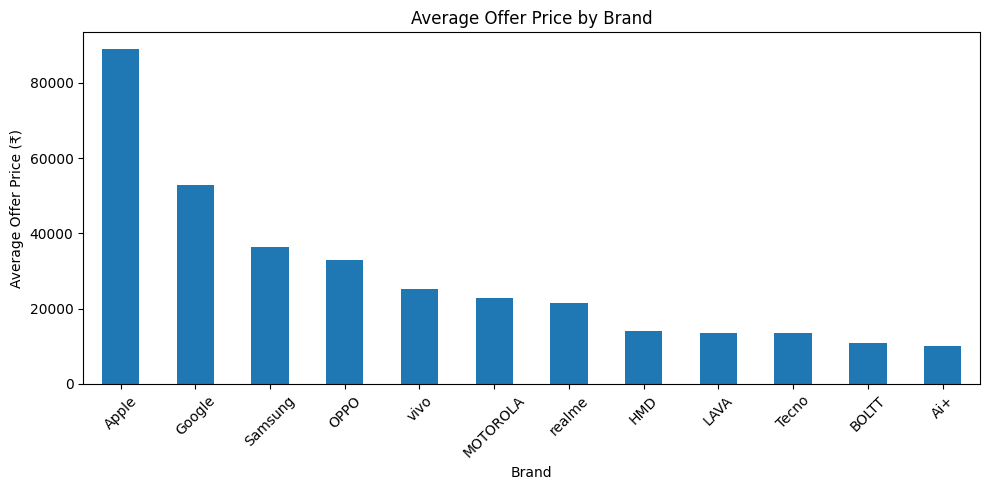

In [ ]:
avg_price = df.groupby('brand')['offer_price'].mean()

avg_price = avg_price.sort_values(ascending=False)


avg_price.plot(kind='bar', figsize=(10, 5))

plt.title('Average Offer Price by Brand')
plt.xlabel('Brand')
plt.ylabel('Average Offer Price (₹)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

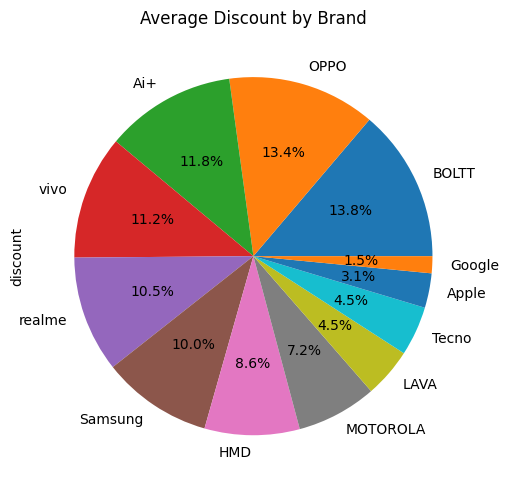

In [ ]:
avg_discount = df.groupby('brand')['discount'].mean()

avg_discount = avg_discount.sort_values(ascending=False)

avg_discount.plot(kind='pie', figsize=(10, 5),autopct='%1.1f%%')

plt.title('Average Discount by Brand')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df[['brand','name','offer_price']].sort_values(by='offer_price',ascending=False).head(5)

,brand,name,offer_price
13,Apple,"Apple iPhone 17 (Black, 256 GB)",88999
19,Samsung,"Samsung Galaxy S25 5G Snapdragon (Icyblue, 128...",58999
11,Samsung,Samsung Galaxy S25 5G Snapdragon (Silver Shado...,58999
20,Samsung,"Samsung Galaxy S25 5G Snapdragon (Mint, 128 GB)",58999
12,Google,"Google Pixel 10a (Berry, 256 GB)",52999


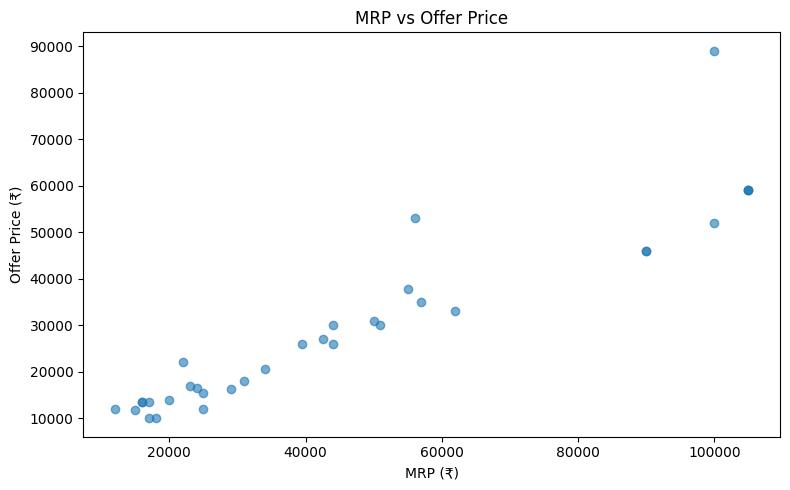

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(df['price'], df['offer_price'], alpha=0.6)

plt.xlabel('MRP (₹)')
plt.ylabel('Offer Price (₹)')
plt.title('MRP vs Offer Price')

plt.tight_layout()
plt.show()

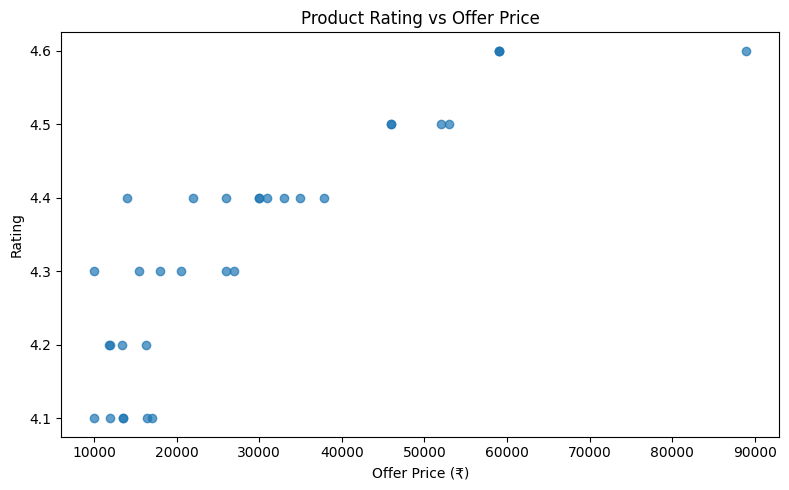

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(df['offer_price'], df['rating'], alpha=0.7)

plt.xlabel('Offer Price (₹)')
plt.ylabel('Rating')
plt.title('Product Rating vs Offer Price')

plt.tight_layout()
plt.show()

In [ ]:
df.groupby('brand')['discount'].mean().sort_values(ascending=False).head(5)

,discount
brand,
BOLTT,48.224497
OPPO,46.774948
Ai+,41.178893
vivo,39.178125
realme,36.747714


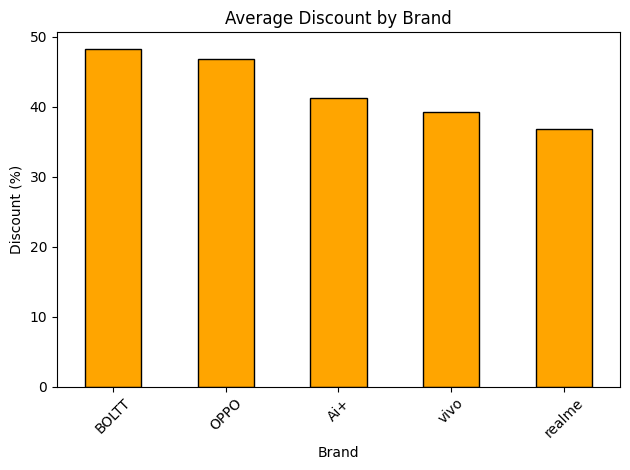

In [ ]:
s=df.groupby('brand')['discount'].mean().sort_values(ascending=False).head(5)
s.plot(kind='bar', color='orange', edgecolor='black')
plt.title('Average Discount by Brand')
plt.xlabel('Brand')
plt.ylabel('Discount (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

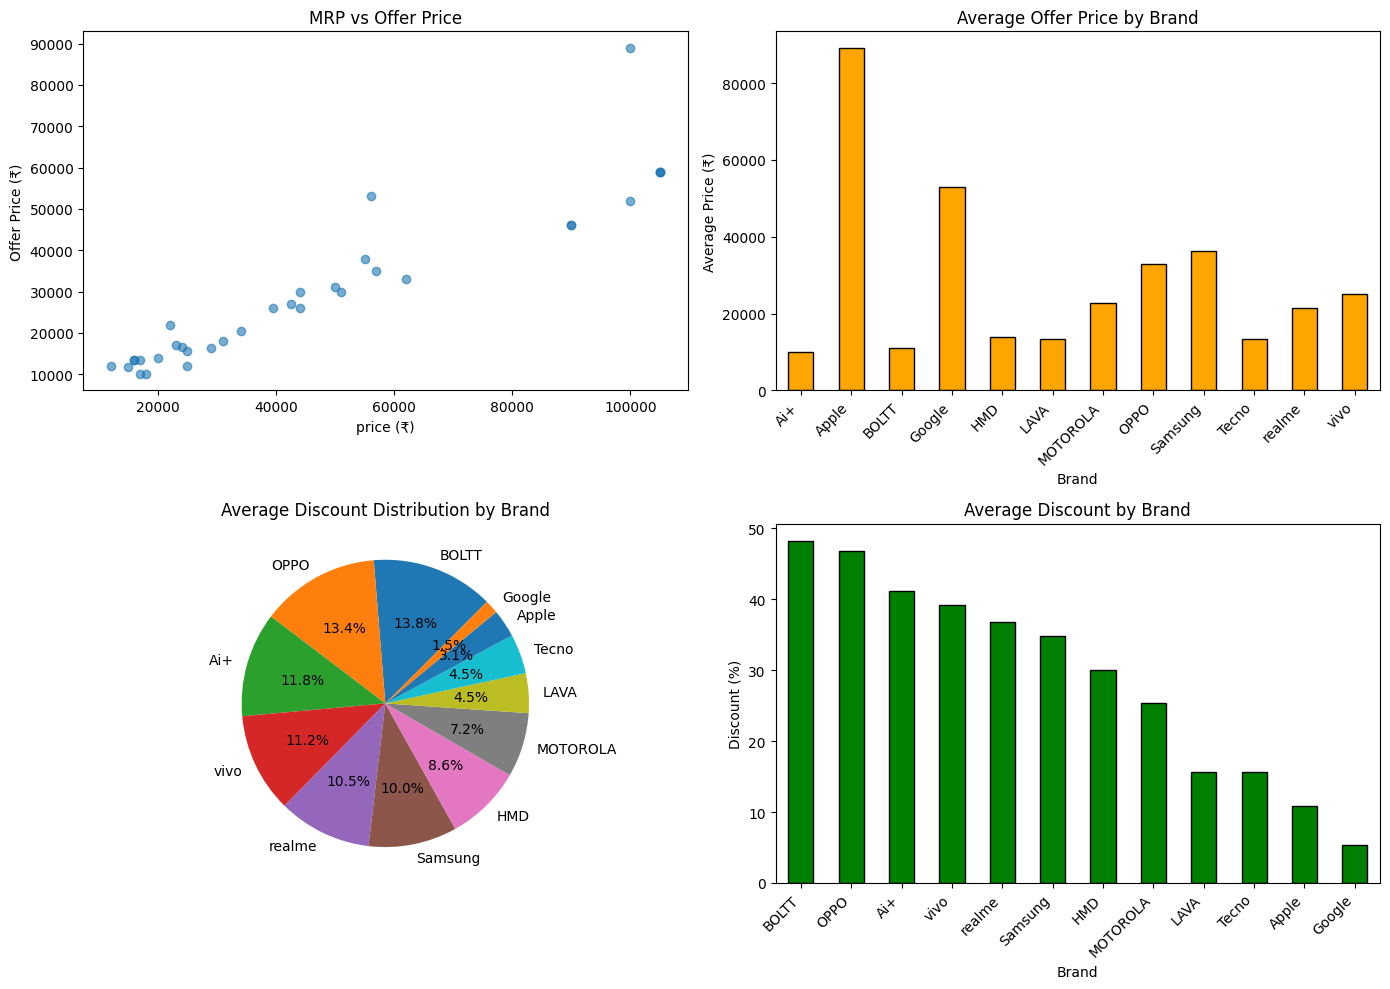

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

# 1. Brand-wise Product Count
plt.subplot(2, 2, 1)
plt.scatter(df['price'], df['offer_price'], alpha=0.6)

plt.xlabel('price (₹)')
plt.ylabel('Offer Price (₹)')
plt.title('MRP vs Offer Price')


# 2. Brand-wise Average Offer Price
plt.subplot(2, 2, 2)
df.groupby('brand')['offer_price'].mean().plot(
    kind='bar', color='orange', edgecolor='black'
)
plt.title('Average Offer Price by Brand')
plt.xlabel('Brand')
plt.ylabel('Average Price (₹)')
plt.xticks(rotation=45, ha='right')

# 3. Average Discount Share (Pie Chart)
plt.subplot(2, 2, 3)
avg_discount = df.groupby('brand')['discount'].mean().sort_values(ascending=False)
avg_discount.plot(kind='pie', autopct='%1.1f%%', startangle=45)
plt.title('Average Discount Distribution by Brand')
plt.ylabel('')  # Hides the default y-label for cleaner look

# 4. Brand-wise Average Discount (Bar Chart)
plt.subplot(2, 2, 4)
avg_discount.plot(kind='bar', color='green', edgecolor='black')
plt.title('Average Discount by Brand')
plt.xlabel('Brand')
plt.ylabel('Discount (%)')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

bins = [0, 15000, 30000, np.inf]

labels = ['Low Range', 'Mid Range', 'High Range']

df['price_range'] = pd.cut(
    df['offer_price'],
    bins=bins,
    labels=labels,
    right=False
)

df[['name', 'brand', 'offer_price', 'price_range']].head(10)

,name,brand,offer_price,price_range
6,MOTOROLA g57 power 5G Snapdragon (Pantone Cors...,MOTOROLA,21999,Mid Range
13,"Apple iPhone 17 (Black, 256 GB)",Apple,88999,High Range
23,MOTOROLA Edge 70 Fusion Snapdragon (Pantone SI...,MOTOROLA,30999,High Range
36,"vivo T5x 5G (Cosmic Green, 256 GB)",vivo,34999,High Range
14,"Samsung Galaxy A36 5G (Dark Blue, 128 GB)",Samsung,25999,Mid Range
29,"Samsung Galaxy A36 5G (Dark Green, 256 GB)",Samsung,29999,Mid Range
20,"Samsung Galaxy S25 5G Snapdragon (Mint, 128 GB)",Samsung,58999,High Range
19,"Samsung Galaxy S25 5G Snapdragon (Icyblue, 128...",Samsung,58999,High Range
11,Samsung Galaxy S25 5G Snapdragon (Silver Shado...,Samsung,58999,High Range
1,"BOLTT EVO (Arctic White, 64 GB)",BOLTT,9999,Low Range


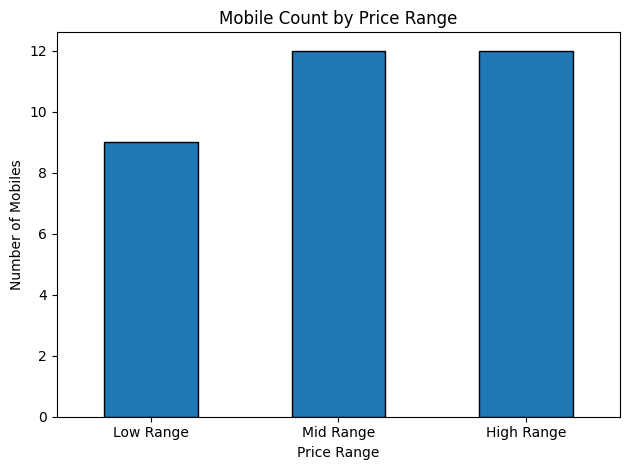

In [ ]:
import matplotlib.pyplot as plt

df['price_range'].value_counts().reindex(labels, fill_value=0).plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Mobile Count by Price Range')
plt.xlabel('Price Range')
plt.ylabel('Number of Mobiles')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()